# Parasites: exploración del dataset

Ejecuta primero los scripts de descarga y preparación del README. Las imágenes y anotaciones son comunes a Faster R-CNN v2 y YOLOv10-S.


In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from matplotlib.patches import Rectangle

from parasite_detection.paths import DATA

if not (DATA / "summary.json").exists():
    raise FileNotFoundError("Con el entorno activado, ejecuta python scripts/prepare_dataset.py desde la raíz del repo.")

summary = json.loads((DATA / "summary.json").read_text())
pd.DataFrame({split: {"images": info["images"], "objects": info["objects"]}
              for split, info in summary.items()}).T

,images,objects
train,1484,3667
val,215,460
test,411,963


## Distribución de especies

Las clases se cuentan por objetos anotados, no por imágenes.


,train,val,test
Fasciola Hepatica,376,40,76
Ascaris Lumbricoides,512,49,115
Enterobius Vermicularis,651,106,154
Hymenolepis,340,43,89
Trichuris Trichiura,445,60,131
Taenia Sp,433,53,168
Schistosoma,413,66,90
Ancylostoma Spp,497,43,140


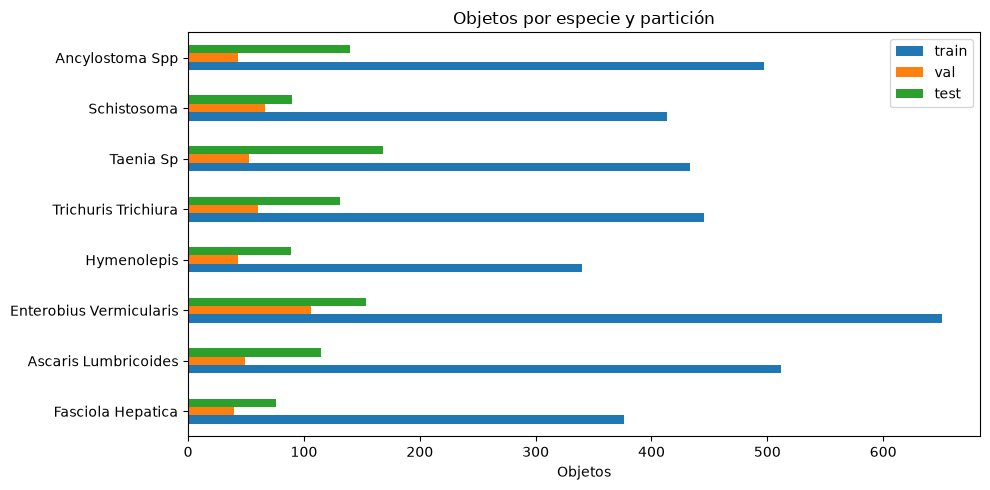

In [2]:
counts = pd.DataFrame({split: info["objects_per_class"] for split, info in summary.items()}).fillna(0).astype(int)
display(counts)
counts.plot.barh(figsize=(10, 5), title="Objetos por especie y partición")
plt.xlabel("Objetos")
plt.tight_layout()

## Ejemplos de entrenamiento

Se muestran cajas COCO originales. Cambia `seed` para explorar otros ejemplos sin modificar las particiones.


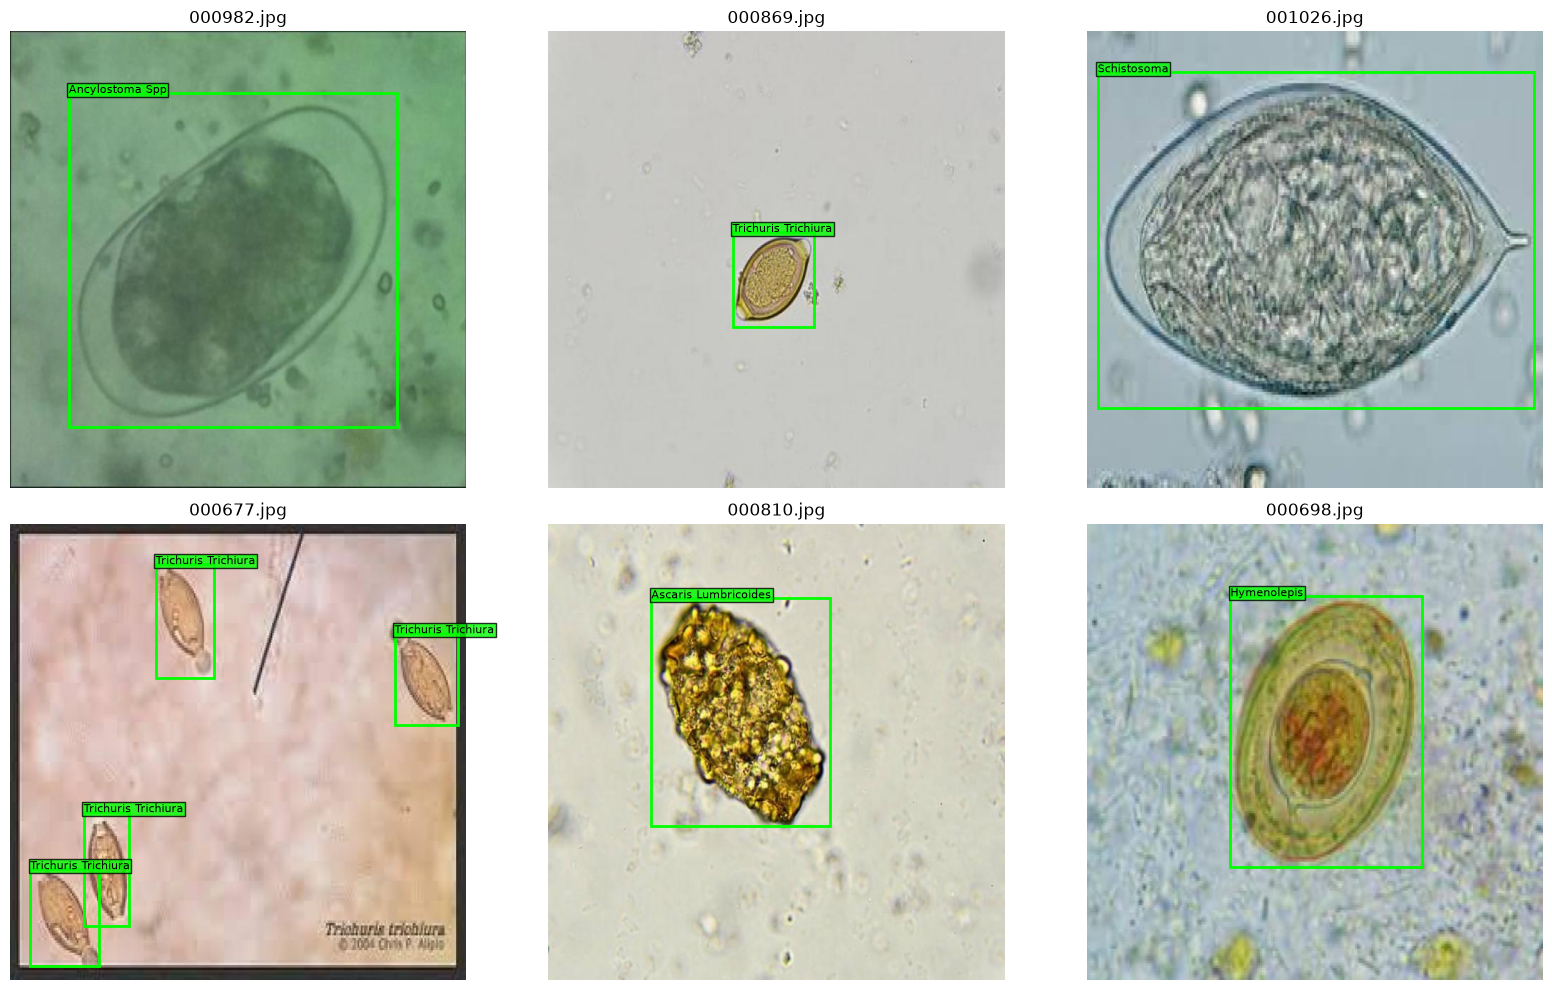

In [3]:
import random

split, seed = "train", 42
coco = json.loads((DATA / "annotations" / f"instances_{split}.json").read_text())
classes = {c["id"]: c["name"] for c in coco["categories"]}
annotations = {}
for ann in coco["annotations"]:
    annotations.setdefault(ann["image_id"], []).append(ann)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, item in zip(axes.flat, random.Random(seed).sample(coco["images"], 6)):
    with Image.open(DATA / "images" / split / item["file_name"]) as image:
        ax.imshow(image)
    for ann in annotations.get(item["id"], []):
        x, y, width, height = ann["bbox"]
        ax.add_patch(Rectangle((x, y), width, height, fill=False, edgecolor="lime", linewidth=2))
        ax.text(x, y, classes[ann["category_id"]], color="black", fontsize=8,
                bbox={"facecolor": "lime", "alpha": 0.8, "pad": 1})
    ax.set_title(item["file_name"])
    ax.axis("off")
plt.tight_layout()

## Correspondencia de etiquetas

COCO y torchvision: 1–8 (0 reservado a background). YOLO: 0–7. Ambos formatos contienen los mismos objetos.


In [4]:
pd.DataFrame(json.loads((DATA / "class_mapping.json").read_text()))

,name,coco_id,torchvision_label,yolo_id
0,Ancylostoma Spp,1,1,0
1,Ascaris Lumbricoides,2,2,1
2,Enterobius Vermicularis,3,3,2
3,Fasciola Hepatica,4,4,3
4,Hymenolepis,5,5,4
5,Schistosoma,6,6,5
6,Taenia Sp,7,7,6
7,Trichuris Trichiura,8,8,7


## Tablas por imagen y por caja

Reunimos los tres splits en dos tablas: una fila por imagen y una fila por caja. Las usan todas las celdas siguientes.

In [5]:
import numpy as np

SPLITS = ["train", "val", "test"]
image_rows, box_rows = [], []
for split in SPLITS:
    coco = json.loads((DATA / "annotations" / f"instances_{split}.json").read_text())
    names = {c["id"]: c["name"] for c in coco["categories"]}
    sizes = {img["id"]: (img["width"], img["height"]) for img in coco["images"]}
    for img in coco["images"]:
        image_rows.append({"split": split, "image_id": img["id"], "file_name": img["file_name"],
                           "width": img["width"], "height": img["height"]})
    for ann in coco["annotations"]:
        x, y, w, h = ann["bbox"]
        img_w, img_h = sizes[ann["image_id"]]
        box_rows.append({"split": split, "image_id": ann["image_id"], "class": names[ann["category_id"]],
                         "x": x, "y": y, "w": w, "h": h, "area": w * h, "aspect": w / h,
                         "rel_side": np.sqrt(w * h / (img_w * img_h))})

images = pd.DataFrame(image_rows)
boxes = pd.DataFrame(box_rows)
images["objects"] = images.set_index(["split", "image_id"]).index.map(
    boxes.groupby(["split", "image_id"]).size()).fillna(0).astype(int)
images["classes"] = images.set_index(["split", "image_id"]).index.map(
    boxes.groupby(["split", "image_id"])["class"].nunique()).fillna(0).astype(int)
print(f"{len(images)} imágenes, {len(boxes)} cajas")

2110 imágenes, 5090 cajas


## Resolución de imagenes

In [6]:
images.groupby(["split", "width", "height"]).size().rename("imágenes").to_frame()

,,,imágenes
split,width,height,
test,640,640,411
train,640,640,1484
val,640,640,215


## Objetos por imagen


,media,mediana,máximo,con_1_objeto,con_5_o_más,varias_especies
split,,,,,,
train,2.47,1.0,57,0.61,0.13,0.06
val,2.14,1.0,20,0.63,0.09,0.05
test,2.34,1.0,27,0.63,0.11,0.05


objects,imagen con <5 objetos,imagen con ≥5 objetos
class,,
Enterobius Vermicularis,0.26,0.74
Ancylostoma Spp,0.46,0.54
Taenia Sp,0.49,0.51
Fasciola Hepatica,0.58,0.42
Trichuris Trichiura,0.59,0.41
Ascaris Lumbricoides,0.68,0.32
Schistosoma,0.70,0.30
Hymenolepis,0.72,0.28


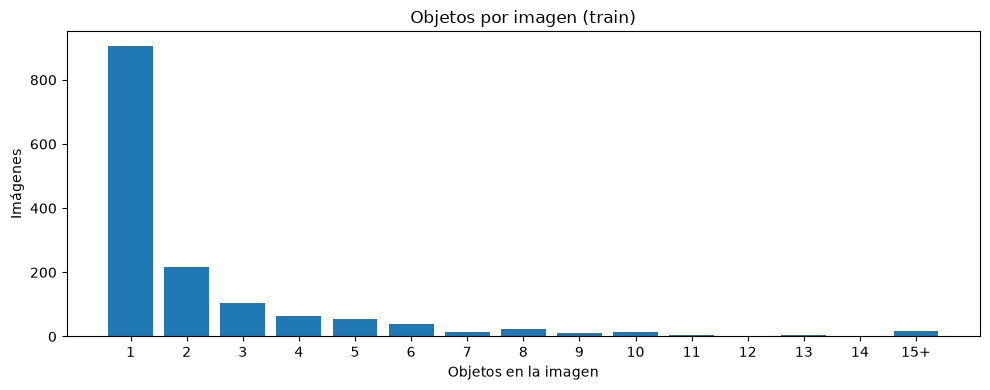

In [7]:
summary_per_image = images.groupby("split").agg(
    media=("objects", "mean"), mediana=("objects", "median"), máximo=("objects", "max"),
    con_1_objeto=("objects", lambda s: (s == 1).mean()),
    con_5_o_más=("objects", lambda s: (s >= 5).mean()),
    varias_especies=("classes", lambda s: (s > 1).mean()))
display(summary_per_image.round(2).loc[SPLITS])

boxes = boxes.merge(images[["split", "image_id", "objects"]], on=["split", "image_id"])
crowded = (pd.crosstab(boxes["class"], boxes["objects"] >= 5, normalize="index")
           .rename(columns={False: "imagen con <5 objetos", True: "imagen con ≥5 objetos"}))
display(crowded.round(2).sort_values("imagen con ≥5 objetos", ascending=False))

fig, ax = plt.subplots(figsize=(10, 4))
counts = images[images["split"] == "train"]["objects"].clip(upper=15).value_counts().sort_index()
ax.bar(counts.index, counts.values)
ax.set_xticks(range(1, 16), [str(i) for i in range(1, 15)] + ["15+"])
ax.set(title="Objetos por imagen (train)", xlabel="Objetos en la imagen", ylabel="Imágenes")
plt.tight_layout()

## Tamaño y forma de las cajas

Categorías COCO: small < 32², medium < 96², large ≥ 96² px². `rel_side` = √(área caja / área imagen).

tamaño_coco,small,medium,large
split,,,
train,0.008,0.262,0.730
val,0.002,0.224,0.774
test,0.037,0.243,0.720


,w,h,rel_side,aspect
class,,,,
Enterobius Vermicularis,80.50,95.50,0.14,0.84
Taenia Sp,101.50,125.75,0.18,0.78
Trichuris Trichiura,119.50,161.50,0.22,0.81
Fasciola Hepatica,126.25,174.75,0.23,0.79
Ancylostoma Spp,133.00,184.50,0.25,0.83
Hymenolepis,157.75,211.50,0.28,0.79
Ascaris Lumbricoides,166.50,220.75,0.30,0.79
Schistosoma,177.50,253.00,0.33,0.86


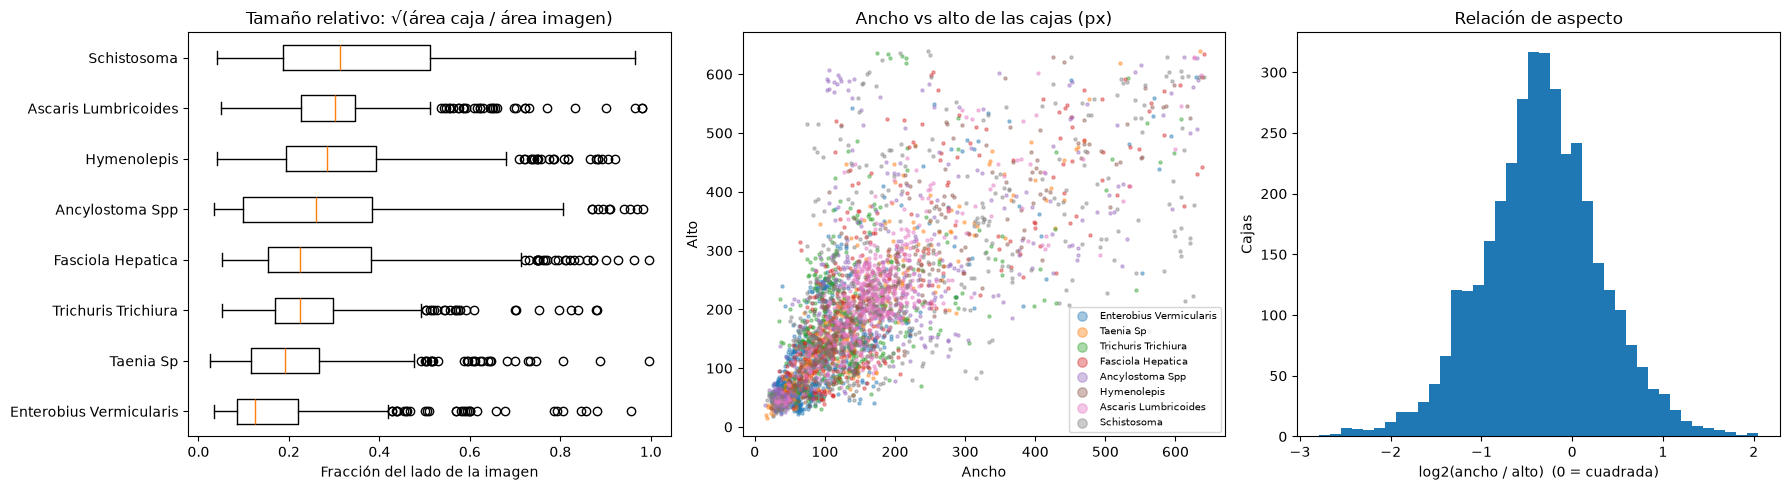

In [8]:
boxes["tamaño_coco"] = pd.cut(boxes["area"], [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
display(pd.crosstab(boxes["split"], boxes["tamaño_coco"], normalize="index").round(3).loc[SPLITS])
display(boxes.groupby("class")[["w", "h", "rel_side", "aspect"]].median().round(2).sort_values("rel_side"))

train_boxes = boxes[boxes["split"] == "train"]
order = train_boxes.groupby("class")["rel_side"].median().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].boxplot([train_boxes.loc[train_boxes["class"] == c, "rel_side"] for c in order],
                orientation="horizontal", tick_labels=order)
axes[0].set(title="Tamaño relativo: √(área caja / área imagen)", xlabel="Fracción del lado de la imagen")
for c in order:
    subset = train_boxes[train_boxes["class"] == c]
    axes[1].scatter(subset["w"], subset["h"], s=5, alpha=0.4, label=c)
axes[1].set(title="Ancho vs alto de las cajas (px)", xlabel="Ancho", ylabel="Alto")
axes[1].legend(fontsize=7, markerscale=3)
axes[2].hist(np.log2(train_boxes["aspect"]), bins=40)
axes[2].set(title="Relación de aspecto", xlabel="log2(ancho / alto)  (0 = cuadrada)", ylabel="Cajas")
plt.tight_layout()

## Aspecto de cada especie

Recortes aleatorios de cada clase para ver la variabilidad dentro de una especie y el parecido entre especies distintas

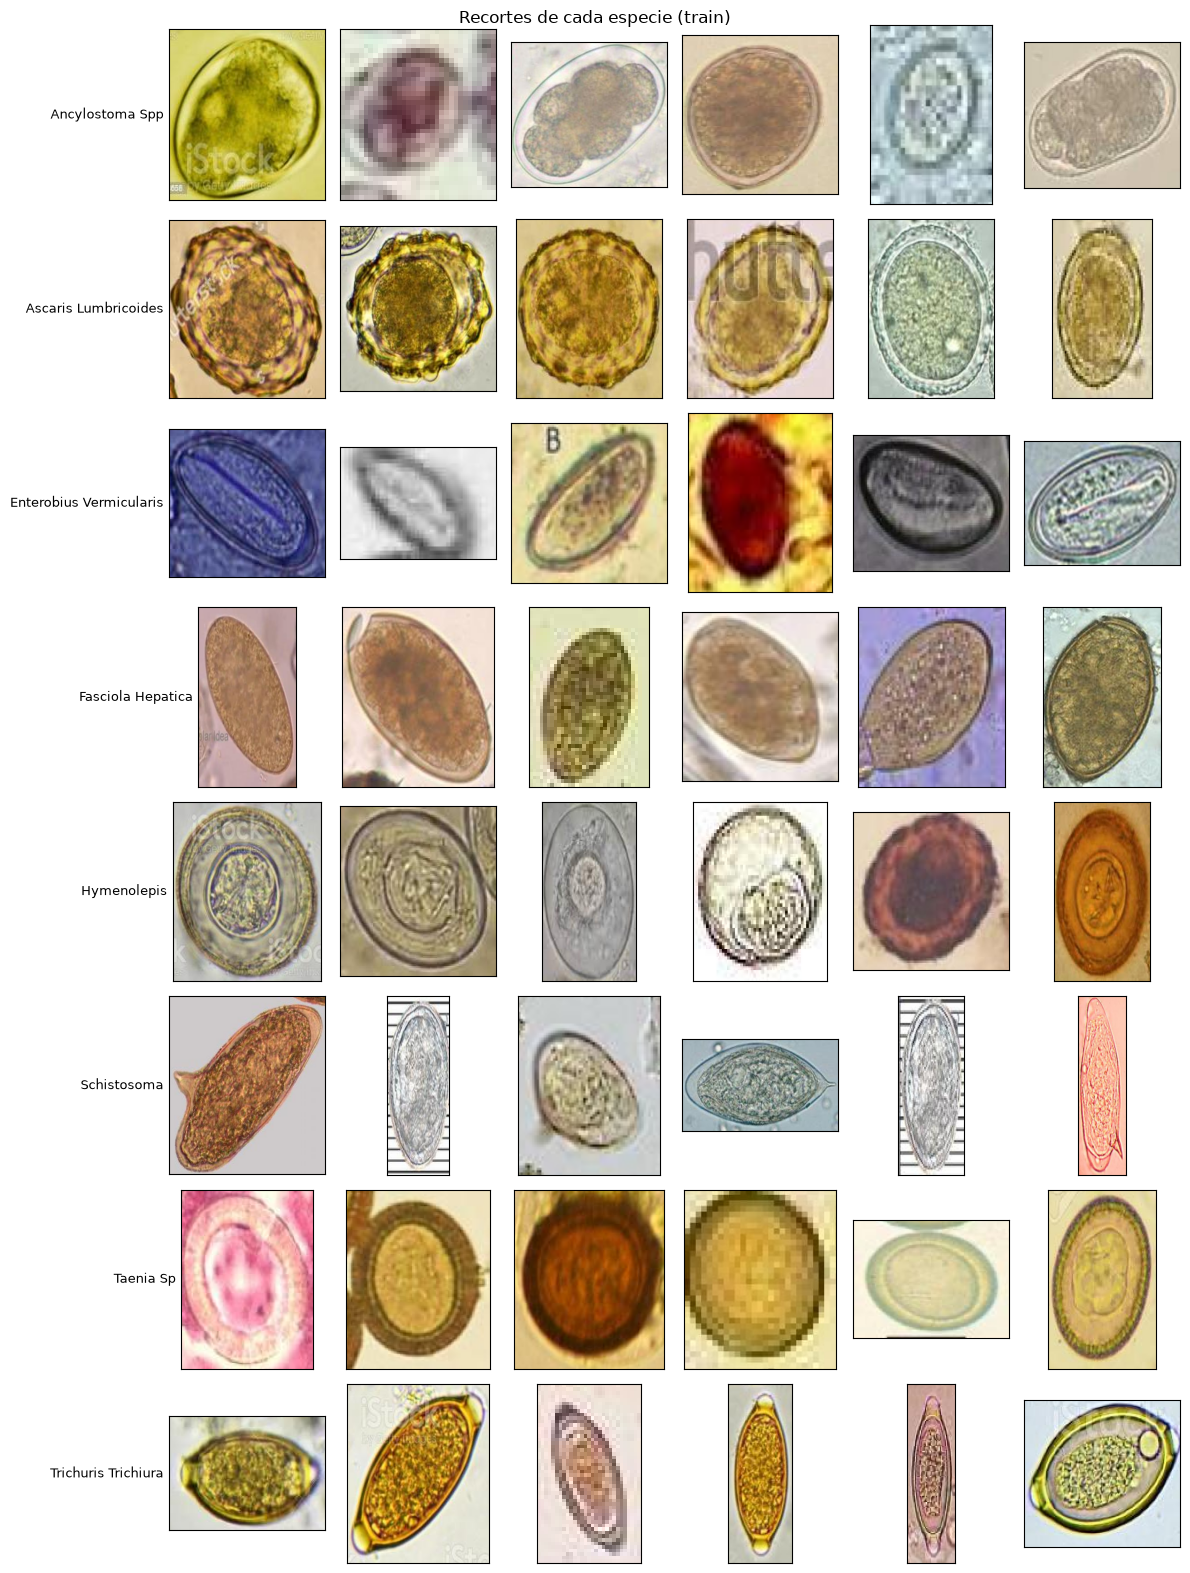

In [9]:
rng = np.random.default_rng(42)
per_class = 6
class_names = sorted(boxes["class"].unique())
fig, axes = plt.subplots(len(class_names), per_class, figsize=(2 * per_class, 2 * len(class_names)))
for row, name in zip(axes, class_names):
    candidates = train_boxes[train_boxes["class"] == name]
    for ax, (_, box) in zip(row, candidates.iloc[rng.choice(len(candidates), per_class, replace=False)].iterrows()):
        file_name = images.loc[(images["split"] == "train") & (images["image_id"] == box["image_id"]), "file_name"].item()
        with Image.open(DATA / "images" / "train" / file_name) as image:
            ax.imshow(image.crop((box["x"], box["y"], box["x"] + box["w"], box["y"] + box["h"])))
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Recortes de cada especie (train)")
plt.tight_layout()

## Color, brillo y contraste

Muestra de 100 imágenes por split. Sirve para justificar los aumentos de color.

R            G            B       brillo       contraste      
        mean   std   mean   std   mean   std   mean   std      mean   std
split                                                                    
train  189.0  38.4  176.1  40.7  158.7  46.2  174.6  38.4      41.9  17.2
val    187.0  34.7  178.0  34.0  164.0  43.8  176.3  33.6      38.2  20.2
test   184.2  43.7  174.3  42.3  160.0  44.2  172.8  40.4      45.6  19.8

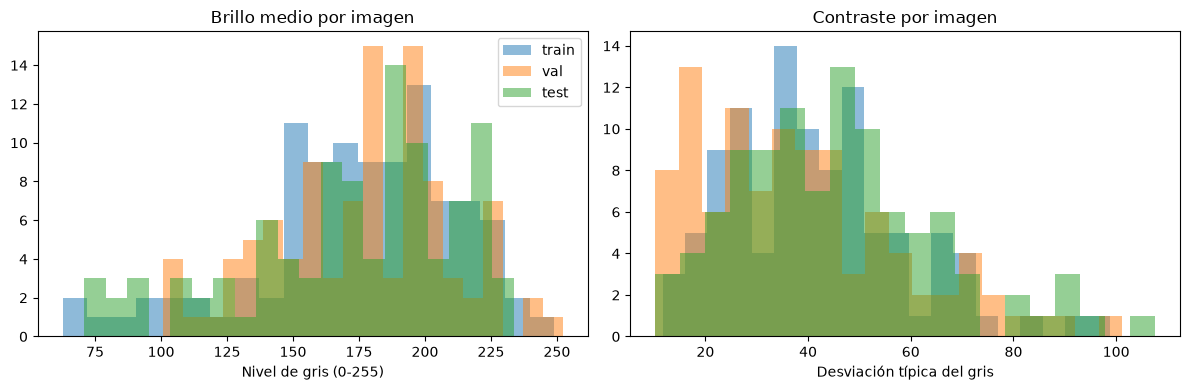

In [10]:
sample = images.groupby("split").sample(100, random_state=42)
colour = []
for item in sample.itertuples():
    with Image.open(DATA / "images" / item.split / item.file_name) as image:
        pixels = np.asarray(image.convert("RGB"), dtype=np.float64)
    gray = pixels.mean(axis=2)
    colour.append({"split": item.split, "R": pixels[..., 0].mean(), "G": pixels[..., 1].mean(),
                   "B": pixels[..., 2].mean(), "brillo": gray.mean(), "contraste": gray.std()})
colour = pd.DataFrame(colour)
display(colour.groupby("split")[["R", "G", "B", "brillo", "contraste"]].agg(["mean", "std"]).round(1).loc[SPLITS])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in SPLITS:
    axes[0].hist(colour.loc[colour["split"] == split, "brillo"], bins=20, alpha=0.5, label=split)
    axes[1].hist(colour.loc[colour["split"] == split, "contraste"], bins=20, alpha=0.5, label=split)
axes[0].set(title="Brillo medio por imagen", xlabel="Nivel de gris (0-255)")
axes[1].set(title="Contraste por imagen", xlabel="Desviación típica del gris")
axes[0].legend()
plt.tight_layout()

## Imagenes casi duplicadas entre train y val/test

Comparamos cada imagen de val y test con todas las de train. Cada imagen se reduce a 32×32 en gris y se normaliza; la similitud es la correlación entre esas versiones reducidas. Con r ≥ 0.98 consideramos que es la misma imagen recomprimida o con un ligero cambio de color. Guardamos la lista para poder evaluar también sobre un test sin duplicados.

,imágenes,casi_duplicadas,fracción
split,,,
test,411,123,0.299
val,215,64,0.298


,0.90,0.95,0.98,0.99
split,,,,
test,157,140,123,122
val,76,68,64,63


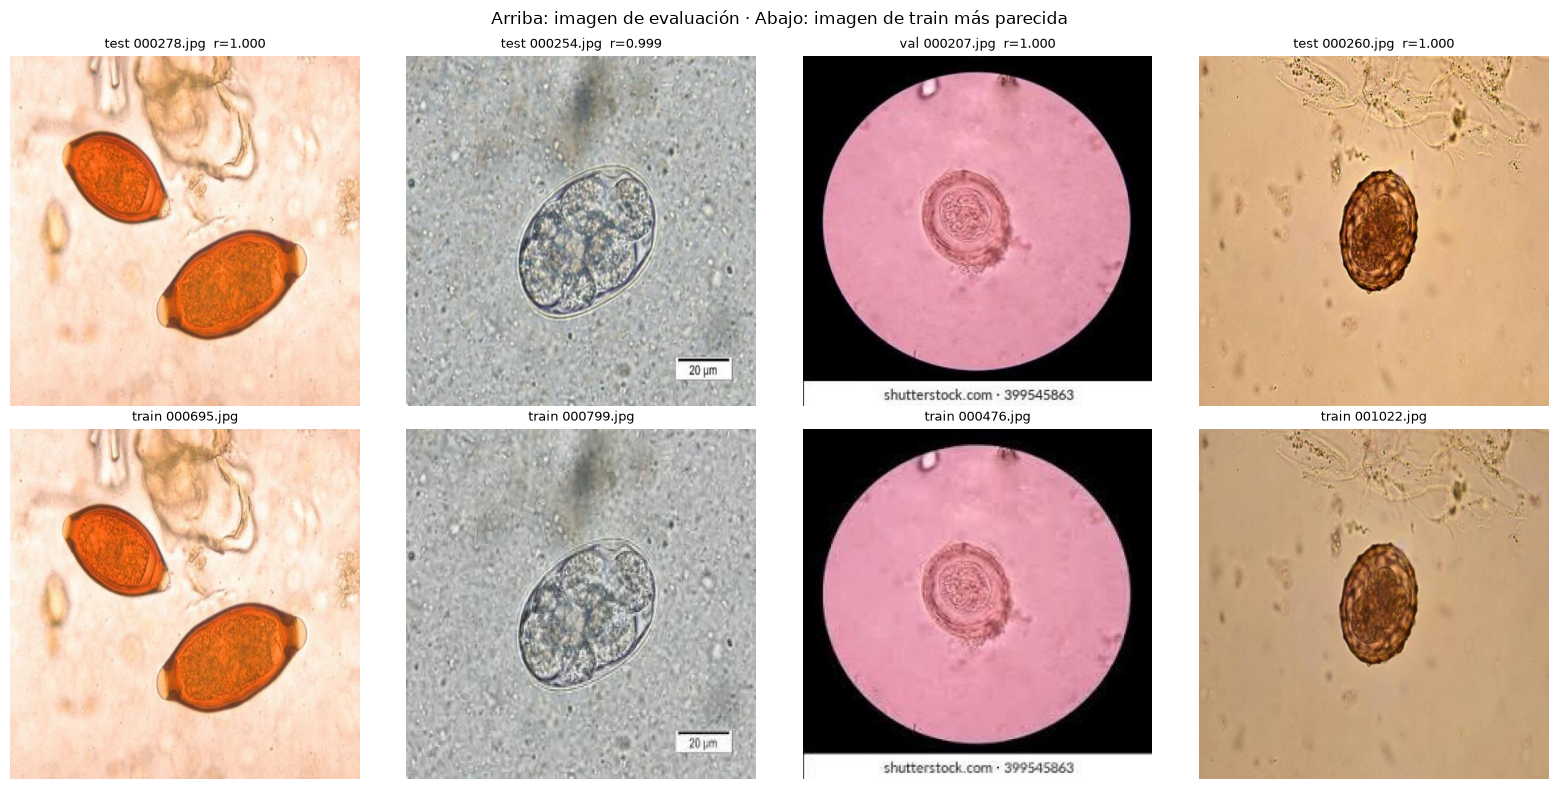

In [11]:
from parasite_detection.paths import RESULTS

def fingerprint(path, size=32):
    with Image.open(path) as image:
        gray = np.asarray(image.convert("L").resize((size, size), Image.BILINEAR), dtype=np.float32).ravel()
    return (gray - gray.mean()) / (gray.std() + 1e-6)

features = np.stack([fingerprint(DATA / "images" / r.split / r.file_name) for r in images.itertuples()])
similarity = features @ features.T / features.shape[1]
np.fill_diagonal(similarity, -1)

THRESHOLD = 0.98
leaks = []
rows_train = np.flatnonzero(images["split"] == "train")
for eval_split in ["val", "test"]:
    rows_eval = np.flatnonzero(images["split"] == eval_split)
    sub = similarity[np.ix_(rows_eval, rows_train)]
    for i, j in enumerate(sub.argmax(axis=1)):
        leaks.append({"split": eval_split, "image_id": images["image_id"].iloc[rows_eval[i]],
                      "file_name": images["file_name"].iloc[rows_eval[i]],
                      "train_file_name": images["file_name"].iloc[rows_train[j]],
                      "similarity": sub[i, j]})
leaks = pd.DataFrame(leaks)
leaks["near_duplicate"] = leaks["similarity"] >= THRESHOLD
display(leaks.groupby("split").agg(imágenes=("image_id", "size"), casi_duplicadas=("near_duplicate", "sum"),
                                   fracción=("near_duplicate", "mean")).round(3))
display(pd.DataFrame({t: leaks.groupby("split")["similarity"].apply(lambda s: (s >= t).sum())
                      for t in [0.90, 0.95, 0.98, 0.99]}))
leaks.to_csv(RESULTS / "metrics" / "eval_train_near_duplicates.csv", index=False)

pairs = leaks[leaks["near_duplicate"]].sample(4, random_state=42)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, pair in enumerate(pairs.itertuples()):
    for row, (split, file_name) in enumerate([(pair.split, pair.file_name), ("train", pair.train_file_name)]):
        with Image.open(DATA / "images" / split / file_name) as image:
            axes[row, col].imshow(image)
        axes[row, col].set_title(f"{split} {file_name}" + (f"  r={pair.similarity:.3f}" if row == 0 else ""), fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("Arriba: imagen de evaluación · Abajo: imagen de train más parecida")
plt.tight_layout()

## Conculisones

- **Resolución única:** todas las imágenes son de 640×640. Roboflow ya las redimensionó, así que entrenar a 640 no pierde información.
- **Objetos grandes:** el 73 % de las cajas son *large* en COCO y menos del 1 % son *small* en train. En test hay un 3,7 % de *small*, sobre todo de Taenia. Mirar APs (AP de objetos pequeños) tiene poco sentido; lo relevante será APm y APl.
- **Tamaño por especie:** Enterobius es la más pequeña (lado mediano ≈ 0,14 de la imagen) y Schistosoma la más grande (≈ 0,33). La varianza dentro de cada clase es alta.
- **Muchos objetos en algunas imágenes:** el 61 % de las imágenes tiene un solo objeto, pero hay imágenes con hasta 57. El 74 % de las cajas de Enterobius está en imágenes con 5 o más objetos. Solo un 5–6 % de las imágenes mezcla especies.
- **Retos visuales:** tinciones y colores muy distintos, recortes pixelados, marcas de agua de bancos de imágenes y huevos con cualquier orientación. Además, Ascaris, Taenia y Hymenolepis se parecen (redondos y marrones). Esto justifica aumentos de rotación de 90°, volteos y cambios de color/HSV.
- **Fuga de datos:** ≈ 30 % de test (123/411) y ≈ 30 % de val (64/215) son casi duplicados de imágenes de train. Las métricas en test serán optimistas. Mantenemos los splits originales, como pide la práctica, pero reportaremos también el mAP en el subconjunto de test sin duplicados (`results/metrics/eval_train_near_duplicates.csv`).

Cosas a tener en cuenta

- La última celda de código crea results/metrics/eval_train_near_duplicates.csv. Es un CSV pequeño y está pensado para subirlo a Git: luego lo usaréis al evaluar los modelos para separar el test con y sin duplicados.
- La fuga de datos es lo más importante para la presentación. La he comprobado mirando parejas de imágenes: son la misma imagen, como mucho con un pequeño cambio de color. Os da un argumento con rigor del que probablemente carezcan otros grupos, y os explica por qué el mAP de test puede salir muy alto.